<a href="https://colab.research.google.com/github/UleleBulele/Economic-Indicators-and-Global-Mental-Health/blob/main/Project_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [3]:
import json

with open("/content/drive/MyDrive/BUSAN300_Project_Rport/GDPfinal.json") as f:
    gdp_data = json.load(f)

GDP = pd.json_normalize(gdp_data)
MHD = pd.read_csv('/content/drive/MyDrive/BUSAN300_Project_Rport/Mental health Depression disorder Data.csv')

/tmp/ipykernel_1243/2077854689.py:7: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  MHD = pd.read_csv('/content/drive/MyDrive/BUSAN300_Project_Rport/Mental health Depression disorder Data.csv')


In [4]:
MHD

,index,Entity,Code,Year,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%)
0,0,Afghanistan,AFG,1990,0.16056,0.697779,0.101855,4.828830,1.677082,4.071831,0.672404
1,1,Afghanistan,AFG,1991,0.160312,0.697961,0.099313,4.829740,1.684746,4.079531,0.671768
2,2,Afghanistan,AFG,1992,0.160135,0.698107,0.096692,4.831108,1.694334,4.088358,0.670644
3,3,Afghanistan,AFG,1993,0.160037,0.698257,0.094336,4.830864,1.705320,4.096190,0.669738
4,4,Afghanistan,AFG,1994,0.160022,0.698469,0.092439,4.829423,1.716069,4.099582,0.669260
...,...,...,...,...,...,...,...,...,...,...,...
108548,108548,Zimbabwe,ZWE,2013,303564.60359,NaN,NaN,NaN,NaN,NaN,NaN
108549,108549,Zimbabwe,ZWE,2014,311665.769283,NaN,NaN,NaN,NaN,NaN,NaN
108550,108550,Zimbabwe,ZWE,2015,320638.507158,NaN,NaN,NaN,NaN,NaN,NaN
108551,108551,Zimbabwe,ZWE,2016,330437.353798,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
disorder_columns = [
    'Schizophrenia (%)', 'Bipolar disorder (%)', 'Eating disorders (%)',
    'Anxiety disorders (%)', 'Drug use disorders (%)',
    'Depression (%)', 'Alcohol use disorders (%)'
]

for col in disorder_columns:
    MHD[col] = pd.to_numeric(MHD[col], errors='coerce')

# Group by 'Entity' (which is the country) and compute the mean for each disorder
CDA = MHD.groupby('Entity')[disorder_columns].mean().reset_index()

# Rename 'Entity' to 'Country' for clarity
CDA.rename(columns={'Entity': 'Country'}, inplace=True)

# Display the result
CDA

,Country,Schizophrenia (%),Bipolar disorder (%),Eating disorders (%),Anxiety disorders (%),Drug use disorders (%),Depression (%),Alcohol use disorders (%)
0,Afghanistan,1.546269e+05,1354.771684,8.034705e+06,4.848102,2.120798,4.118622,0.663151
1,Africa,NaN,NaN,3.805273e+08,NaN,NaN,NaN,NaN
2,Albania,1.657342e+04,701.914990,1.207085e+06,3.368903,0.498765,2.190442,1.746757
3,Algeria,2.641227e+05,1161.691462,9.765230e+06,5.011396,1.540640,3.657743,0.653712
4,American Samoa,3.372609e+02,944.272482,3.315479e+04,3.293312,0.759355,2.940850,1.135266
...,...,...,...,...,...,...,...,...
271,Western Sub-Saharan Africa,1.966169e+06,1239.026300,1.242002e-01,2.878408,0.465229,3.745352,0.945113
272,World,5.394419e+07,1129.563996,2.749910e+09,3.792096,0.914003,3.504355,1.452807
273,Yemen,1.559495e+05,1320.053647,5.709010e+06,4.833025,1.243692,4.004947,0.631849
274,Zambia,6.915189e+04,1172.397184,2.903535e+06,3.560979,0.510522,3.553940,1.639368


In [6]:
GDP

,Country,Population Rank,Growth Rate,World Percentage,Density,Land Area,2020 Population Rank,2020 World Percentage,2020 Growth Rate,Area,Capital City,Region,Subregion,Anthem,Government,GDP (IMF),GDP (UN),GDP Per Capita
0,Spain,30,0.04%,0.60%,92.40,"498,800",30,0.60%,0.04%,"505,992",Madrid,Europe,Southern Europe,Spain,Spain,$1.50 Tn,$1.24 Tn,"$32,019.83"
1,Cyprus,158,0.73%,0.02%,130.51,"9,240",158,0.02%,0.73%,"9,251",Nicosia,Europe,Eastern Europe,NaN,NaN,$26.35 Bn,$20.05 Bn,"$21,822.84"
2,Bahrain,152,3.68%,0.02%,2224.28,760,152,0.02%,3.68%,765,Manama,Asia,Western Asia,NaN,NaN,$40.71 Bn,$32.18 Bn,"$23,923.13"
3,Bhutan,165,1.12%,0.01%,20.10,"38,117",165,0.01%,1.12%,"38,394",Thimphu,Asia,Southern Asia,NaN,NaN,$2.94 Bn,$2.21 Bn,"$3,808.93"
4,Singapore,114,0.79%,0.08%,8239.92,700,114,0.08%,0.79%,710,Singapore,Asia,South-Eastern Asia,NaN,NaN,$391.88 Bn,$296.95 Bn,"$66,983.26"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179,Venezuela,50,-0.28%,0.36%,31.03,"882,050",50,0.36%,-0.28%,"916,445",Caracas,Americas,South America,NaN,Venezuela,$70.11 Bn,$291.38 Bn,"$2,465.4"
180,Brazil,6,0.72%,2.73%,24.96,"8,358,140",6,2.73%,0.72%,"8,515,767",Brasília,Americas,South America,Brazil,Brazil,$2.06 Tn,$1.80 Tn,"$9,703.17"
181,United Kingdom,21,0.53%,0.87%,279.48,"241,930",21,0.87%,0.53%,"242,900",London,Europe,Northern Europe,United Kingdom,United Kingdom,$2.93 Tn,$2.65 Tn,"$43,117.57"
182,Japan,11,-0.30%,1.62%,334.66,"364,555",11,1.62%,-0.30%,"377,930",Tokyo,Asia,Eastern Asia,Japan,Japan,$5.50 Tn,$4.94 Tn,"$43,450.14"


In [7]:
GDP.columns

Index(['Country', 'Population Rank', 'Growth Rate', 'World Percentage',
       'Density', 'Land Area', '2020 Population Rank', '2020 World Percentage',
       '2020 Growth Rate', 'Area', 'Capital City', 'Region', 'Subregion',
       'Anthem', 'Government', 'GDP (IMF)', 'GDP (UN)', 'GDP Per Capita'],
      dtype='object')

In [8]:
CDA.columns

Index(['Country', 'Schizophrenia (%)', 'Bipolar disorder (%)',
       'Eating disorders (%)', 'Anxiety disorders (%)',
       'Drug use disorders (%)', 'Depression (%)',
       'Alcohol use disorders (%)'],
      dtype='object')

In [9]:
def clean_gdp(val):
    if isinstance(val, str):
        val = val.replace("$", "")
        val = val.replace("-", "")
        if "Tn" in val:
            return float(val.replace(" Tn", "")) * 1e12
        elif "Bn" in val:
            return float(val.replace(" Bn", "")) * 1e9
        elif "Mn" in val:
            return float(val.replace(" Mn", "")) * 1e6
        elif "Th" in val:
            return float(val.replace(" Th", "")) * 1e3
    return val

GDP["GDP (IMF)"] = GDP["GDP (IMF)"].apply(clean_gdp)
GDP['GDP (UN)'] = GDP['GDP (UN)'].apply(clean_gdp)

GDP['GDP Per Capita'] = GDP['GDP Per Capita'].replace('[\$,]', '', regex=True).astype(float)

<>:18: SyntaxWarning: invalid escape sequence '\$'
<>:18: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_1243/1775044636.py:18: SyntaxWarning: invalid escape sequence '\$'
  GDP['GDP Per Capita'] = GDP['GDP Per Capita'].replace('[\$,]', '', regex=True).astype(float)


In [10]:
GDP['Country'] = GDP['Country'].str.upper()
GDP['Country'] = GDP['Country'].str.strip()
CDA['Country'] = CDA['Country'].str.upper()
CDA['Country'] = CDA['Country'].str.strip()

combined_df = pd.merge(CDA, GDP, left_on='Country', right_on='Country', how='inner')

In [11]:
combined_df = combined_df.drop(['Anthem', 'Government'], axis=1)
combined_df = combined_df.dropna()
print(combined_df.isnull().sum())
print(combined_df['Country'].nunique())

Country                      0
Schizophrenia (%)            0
Bipolar disorder (%)         0
Eating disorders (%)         0
Anxiety disorders (%)        0
Drug use disorders (%)       0
Depression (%)               0
Alcohol use disorders (%)    0
Population Rank              0
Growth Rate                  0
World Percentage             0
Density                      0
Land Area                    0
2020 Population Rank         0
2020 World Percentage        0
2020 Growth Rate             0
Area                         0
Capital City                 0
Region                       0
Subregion                    0
GDP (IMF)                    0
GDP (UN)                     0
GDP Per Capita               0
dtype: int64
173


In [12]:
combined_df.to_excel("combined_dataset.xlsx", index=False)

In [13]:
conditions = ['Population Rank', 'GDP Per Capita', 'GDP (IMF)', 'GDP (UN)', 'Schizophrenia (%)', 'Bipolar disorder (%)',
       'Eating disorders (%)', 'Anxiety disorders (%)',
       'Drug use disorders (%)', 'Depression (%)',
       'Alcohol use disorders (%)']

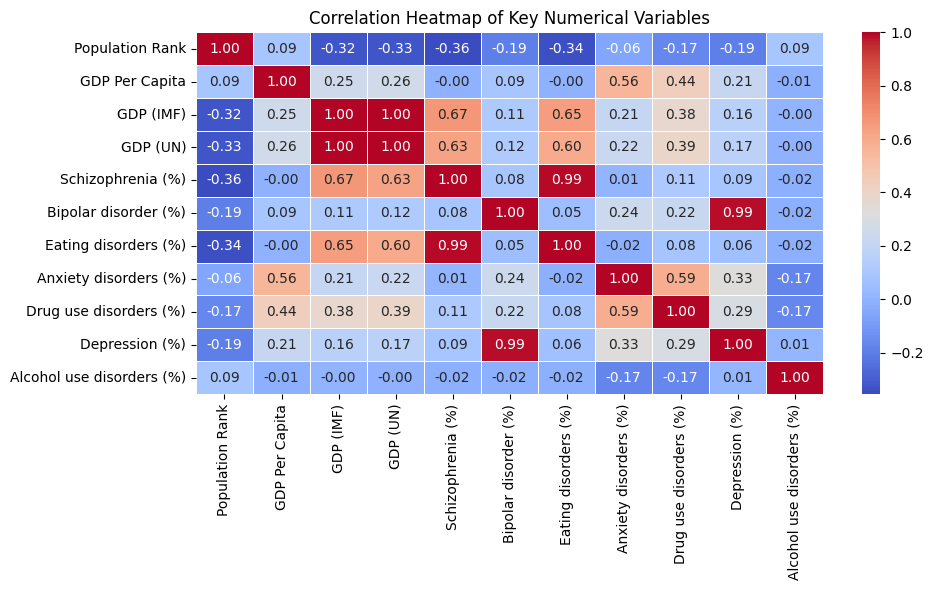

In [14]:
for col in conditions:
    combined_df[col] = pd.to_numeric(combined_df[col], errors='coerce')

plt.figure(figsize=(10, 6))
correlation_matrix = combined_df[conditions].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Key Numerical Variables')
plt.tight_layout()

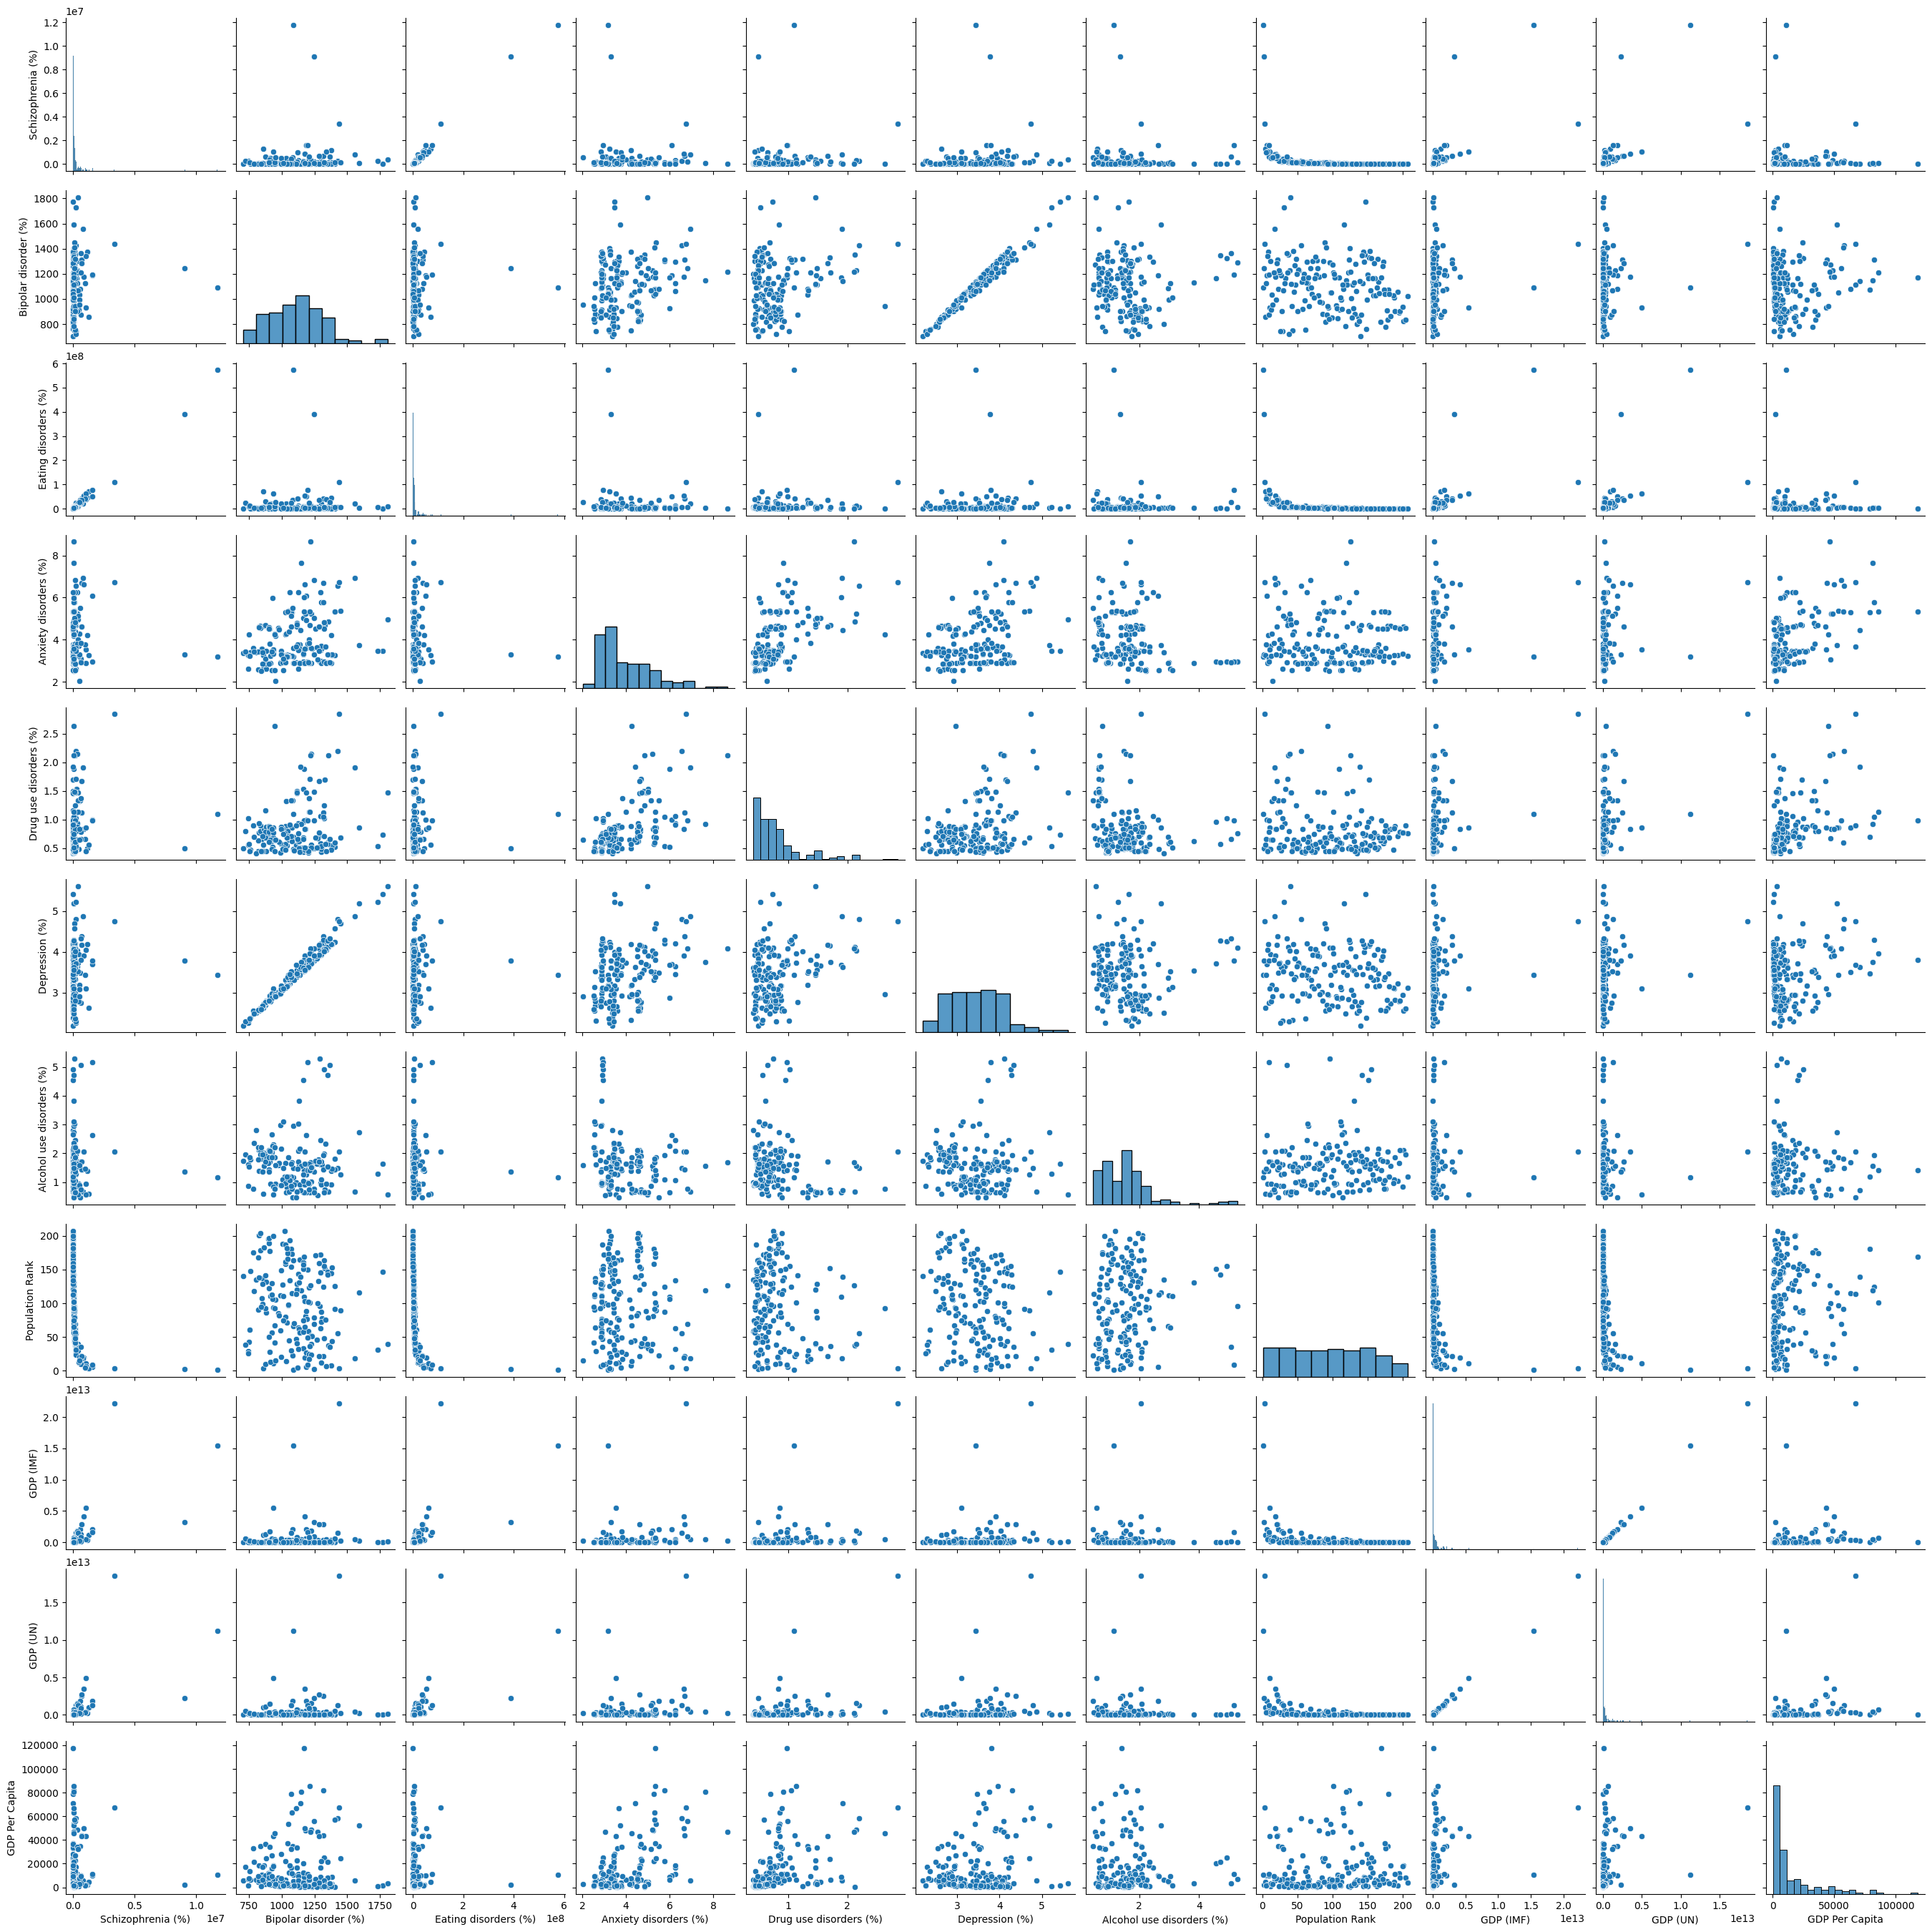

In [15]:
sns.pairplot(data=combined_df)

<Axes: xlabel='Depression (%)', ylabel='GDP Per Capita'>

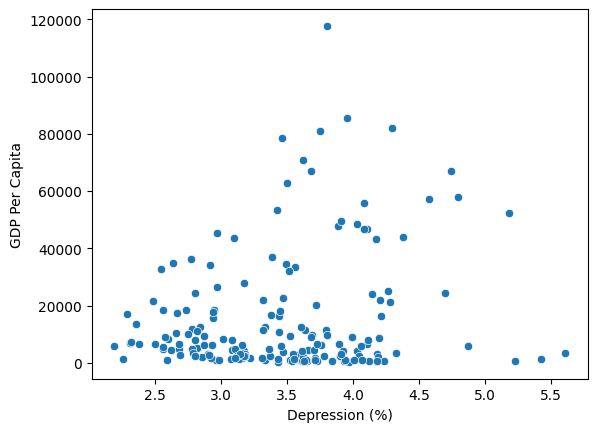

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=combined_df, y='GDP Per Capita', x='Depression (%)')

<Axes: xlabel='Anxiety disorders (%)', ylabel='GDP Per Capita'>

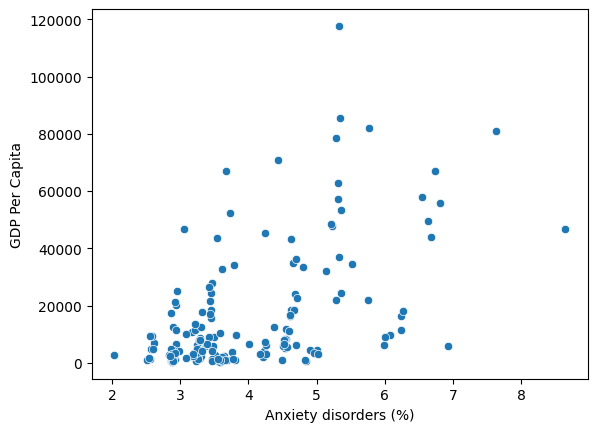

In [17]:
sns.scatterplot(data=combined_df, y='GDP Per Capita', x='Anxiety disorders (%)')

<Axes: xlabel='Drug use disorders (%)', ylabel='GDP Per Capita'>

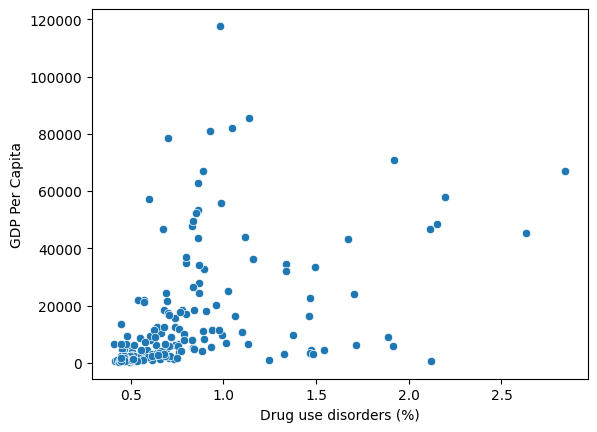

In [18]:
sns.scatterplot(data=combined_df, y='GDP Per Capita', x='Drug use disorders (%)')